In [1]:
# Transfer Learning with a Pretrained CNN
# o Load a pretrained model (e.g., ResNet50 or VGG16).
# o Fine-tune it on a small custom dataset (e.g., cats vs dogs).
# o Freeze layers and experiment with performance

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

/Users/sahilpatil/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/train",
    image_size=(160, 160),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/validation",
    image_size=(160, 160),
    batch_size=32
)

print("Classes:", train_ds.class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [4]:
preprocess = tf.keras.applications.resnet50.preprocess_input

train_ds = train_ds.map(lambda x, y: (preprocess(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess(x), y))

In [5]:
base = ResNet50(weights=None, include_top=False,
                input_shape=(160, 160, 3))

base.load_weights("dataset/resnet50_weights.h5")

base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [6]:
# Train with frozen layers

h1 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss1, acc1 = model.evaluate(val_ds)

print("Frozen Model Accuracy:", acc1 * 100, "%")

Epoch 1/3
63/63 [==============================] - 15s 197ms/step - loss: 0.2823 - accuracy: 0.9270 - val_loss: 0.1081 - val_accuracy: 0.9620
Epoch 2/3
63/63 [==============================] - 11s 172ms/step - loss: 0.0447 - accuracy: 0.9825 - val_loss: 0.0534 - val_accuracy: 0.9780
Epoch 3/3
32/32 [==============================] - 4s 111ms/step - loss: 0.0550 - accuracy: 0.9790
Frozen Model Accuracy: 97.89999723434448 %


In [7]:
# Fine Tune ResNet 50
base.trainable = True

for layer in base.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.00001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

h2 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss2, acc2 = model.evaluate(val_ds)

print("Fine-tuned Model Accuracy:", acc2 * 100, "%")

Epoch 1/3


2026-11-16 20:49:03.910544: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node Adam/AssignAddVariableOp.


63/63 [==============================] - 18s 240ms/step - loss: 0.0393 - accuracy: 0.9880 - val_loss: 0.0529 - val_accuracy: 0.9790
Epoch 2/3
63/63 [==============================] - 15s 234ms/step - loss: 0.0184 - accuracy: 0.9975 - val_loss: 0.0535 - val_accuracy: 0.9770
Epoch 3/3
32/32 [==============================] - 5s 139ms/step - loss: 0.0531 - accuracy: 0.9780
Fine-tuned Model Accuracy: 97.79999852180481 %


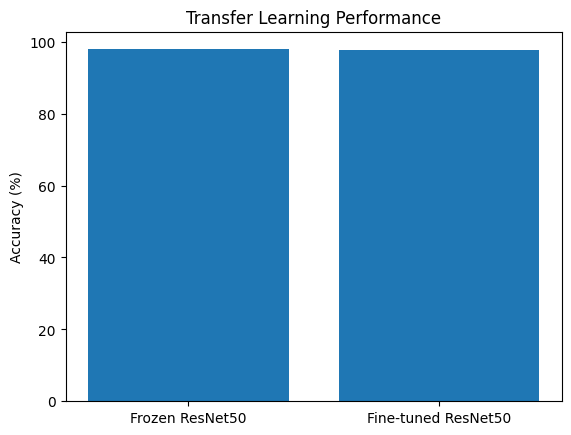

In [8]:
# Compare
plt.bar(['Frozen ResNet50', 'Fine-tuned ResNet50'],
        [acc1 * 100, acc2 * 100])

plt.ylabel("Accuracy (%)")
plt.title("Transfer Learning Performance")
plt.show()

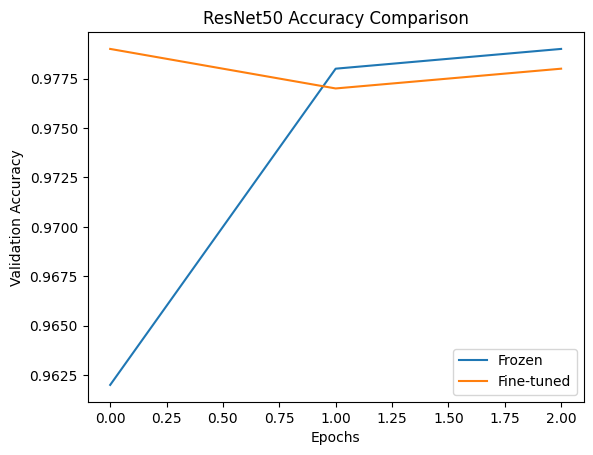

In [9]:
# Plot accuracy
plt.plot(h1.history['val_accuracy'], label='Frozen')
plt.plot(h2.history['val_accuracy'], label='Fine-tuned')

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("ResNet50 Accuracy Comparison")
plt.legend()
plt.show()